# Learning module 14 — Enter the scenario query and observe its results

**Small milestone:** require Search to be visible, uniquely locate its input, replace existing text with the scenario's query, and observe the current-query result state. Capture before/after evidence and close the session. We do not open a movie or verify its details yet.

The business value comes from `scenario_input["search_query"]`, currently `Interstellar`. The native input locator comes from app knowledge and runtime inspection: `movies.search.query.input`. They serve different purposes; the movie query is not a locator.

The new state-changing calls are:

```python
query_input.clear()          # Once, if the field currently contains text.
query_input.send_keys(query) # Once, after verifying the cleared field.
```

We verify the unique native input's name, type, visibility, and enabled state, and reacquire it after clearing. We record attempted/acknowledged states separately and do not automatically repeat either write if a response fails. Read-only polling can repeat. [Appium client element APIs](https://appium.github.io/python-client-sphinx/webdriver.html#module-appium.webdriver.webelement)

### What we learned from this app's source

- `search_view.dart` defines the Search screen and input semantics identifiers.
- `search_viewmodel.dart` starts search after a **350 ms** typing pause. Normalization trims whitespace; no submit/newline is required for this exercise.
- Existing cards and their displayed-query heading can remain during a new request. We must see the exact heading `Results for “Interstellar”` and current input value before treating the new results as observed.
- A visible `movies.search.results.error` blocks accepting retained cards. A completed empty response (`No movies match this title.`) is recorded separately from a timeout.

XCUITest/WDA can return a text field's placeholder as its `value` when actual text is empty. The exercise reads `placeholderValue` too and records whether the observed value is placeholder/empty. That is a UI observation, not direct access to Flutter's view-model state. [Native element attributes](https://appium.github.io/appium-xcuitest-driver/latest/reference/element-attributes/)

**Prerequisites:** run this notebook's setup cells. Leave the app on Search by completing module 13 first. This exercise does not navigate there automatically. It revalidates the device/app, opens a new session, and uses the same independent XML/PNG captures and cleanup pattern. Run serially on the selected Simulator. Earlier dependency findings remain unresolved.

The normal configured app supplies its own data; the notebook supplies no fixture results or replacement API responses. UI results alone do not prove a fresh network request—the app's repository supports cached reads. A query result, a matching movie title, the correct release year, and a full scenario pass remain different claims.


## This notebook

Part **14 — Enter Interstellar and observe results** of the learning sequence. [Notebook index](README.md).

Select the project's `.venv` Python kernel and run this notebook from top to bottom. Its Python setup is included locally; running another notebook in another kernel does not populate this one's variables or PATH. The supported working directories are the project root, `server/`, and `server/sample_scenarios/`.

**Execution scope:** Requires Search root; clears/types the query as documented.

Saved lesson outputs and embedded screenshots are historical snapshots preserved during the split on November 3, 2026. Newly included setup cells have no saved outputs. Rerunning an executable scenario creates fresh local artifacts; these continue living in `server/.tools/`, not beside the notebooks.

**App-state prerequisite:** Python setup does not navigate the app. Leave Search root visible using [lesson 13](13_search_navigation.ipynb). If Search is on a retained details page, use its Back control first.

### Setup for this notebook

These source-only prerequisite cells are repeated intentionally so the lesson is runnable in a fresh kernel. They configure local values/environment and inspect tool versions; they do not launch an Appium server, create a session, or tap/type in the app. The original lessons remain linked for explanation.


In [1]:
# Setup: Sample scenario input (lesson 01)
from pprint import pprint

scenario_text = (
    "In Movies, search for Interstellar, open the 2014 movie, "
    "and verify that its details show the title Interstellar "
    "and release year 2014."
)

scenario_input = {
    "instruction": scenario_text,
    "application_name": "Movies",
    "application_profile_ref": None,
    "requested_actions": [
        "search_for_movie",
        "open_matching_movie_details",
    ],
    "search_query": "Interstellar",
    "target_item_identity": {"title": "Interstellar", "release_year": 2014},
    "expected_title": "Interstellar",
    "expected_release_year": 2014,
    "title_matching_rule": "exact",  # Proposed comparison rule for this exercise.
}

pprint(scenario_input, sort_dicts=False)


{'instruction': 'In Movies, search for Interstellar, open the 2014 movie, and '
                'verify that its details show the title Interstellar and '
                'release year 2014.',
 'application_name': 'Movies',
 'application_profile_ref': None,
 'requested_actions': ['search_for_movie', 'open_matching_movie_details'],
 'search_query': 'Interstellar',
 'target_item_identity': {'title': 'Interstellar', 'release_year': 2014},
 'expected_title': 'Interstellar',
 'expected_release_year': 2014,
 'title_matching_rule': 'exact'}


In [2]:
# Setup: Recorded run profile (lesson 03)
from pprint import pprint

run_profile = {
    "id": "movies-ios-local",
    "platform": "ios",
    "execution_provider": "local",
    "app_bundle_id": "com.example.movies",
    "simulator_udid": "4F0707AE-45BC-464D-9099-6EE76C3740A9",
}

app_profiles = {run_profile["id"]: run_profile}
scenario_input["application_profile_ref"] = run_profile["id"]
selected_profile = app_profiles[scenario_input["application_profile_ref"]]

print("Scenario profile reference:", scenario_input["application_profile_ref"])
pprint(selected_profile, sort_dicts=False)


Scenario profile reference: movies-ios-local
{'id': 'movies-ios-local',
 'platform': 'ios',
 'execution_provider': 'local',
 'app_bundle_id': 'com.example.movies',
 'simulator_udid': '4F0707AE-45BC-464D-9099-6EE76C3740A9'}


In [3]:
# Setup: Local Node activation (lesson 05)
import os
from pathlib import Path
import shutil
import subprocess

notebook_cwd = Path.cwd().resolve()
server_candidates = (notebook_cwd, notebook_cwd / "server", *notebook_cwd.parents)
server_dir = next((candidate for candidate in server_candidates
                   if (candidate / ".node-version").is_file()
                   and (candidate / "package.json").is_file()
                   and (candidate / "sample_scenarios").is_dir()), None)
if server_dir is None:
    raise RuntimeError("Run from the project root, server, or sample_scenarios folder.")

node_version = (server_dir / ".node-version").read_text().strip()
node_bin = server_dir / ".tools" / f"node-v{node_version}-darwin-arm64" / "bin"
if not (node_bin / "node").is_file():
    raise FileNotFoundError(f"Project-local Node is missing: {node_bin}")

path_entries = [entry for entry in os.environ.get("PATH", "").split(os.pathsep)
                if entry != str(node_bin)]
os.environ["PATH"] = os.pathsep.join([str(node_bin), *path_entries])

print("Selected Node:", shutil.which("node"))
print("Node version:", subprocess.check_output(["node", "--version"], text=True, timeout=10).strip())
print("npm version:", subprocess.check_output(["npm", "--version"], text=True, timeout=10).strip())


Selected Node: /Users/tarunkhurana/Engineering/projects/tarunkhurana2015/ai-certification-gen-academy/week3-project-automated-testing/server/.tools/node-v24.22.2-darwin-arm64/bin/node
Node version: v24.22.2
npm version: 11.19.1


In [4]:
# Setup: Local Appium activation (lesson 06)
import json
import os
import shutil
import subprocess

if "server_dir" not in globals() or "node_bin" not in globals():
    raise RuntimeError("Run the Node setup cell in this notebook first.")
if shutil.which("node") != str(node_bin / "node"):
    raise RuntimeError("Reactivate the project-local Node runtime first.")

appium_bin_dir = server_dir / "node_modules" / ".bin"
appium_executable = appium_bin_dir / "appium"
if not appium_executable.is_file():
    raise FileNotFoundError("The project-local Appium package is missing.")

os.environ["APPIUM_HOME"] = str(server_dir / ".tools" / "appium")
os.environ["npm_config_cache"] = str(server_dir / ".tools" / "npm-cache")
path_entries = [entry for entry in os.environ.get("PATH", "").split(os.pathsep)
                if entry != str(appium_bin_dir)]
os.environ["PATH"] = os.pathsep.join([str(appium_bin_dir), *path_entries])

expected_version = json.loads((server_dir / "package.json").read_text())["devDependencies"]["appium"]
actual_version = subprocess.check_output(
    [str(appium_executable), "--version"], cwd=server_dir, text=True, timeout=30
).strip()
if actual_version != expected_version:
    raise RuntimeError(f"Expected Appium {expected_version}, found {actual_version}.")

print("Selected Appium:", shutil.which("appium"))
print("Appium version:", actual_version)
print("Appium home:", os.environ["APPIUM_HOME"])


Selected Appium: /Users/tarunkhurana/Engineering/projects/tarunkhurana2015/ai-certification-gen-academy/week3-project-automated-testing/server/node_modules/.bin/appium
Appium version: 3.9.0
Appium home: /Users/tarunkhurana/Engineering/projects/tarunkhurana2015/ai-certification-gen-academy/week3-project-automated-testing/server/.tools/appium


dbug Appium Creating hash file directory: /Users/tarunkhurana/Engineering/projects/tarunkhurana2015/ai-certification-gen-academy/week3-project-automated-testing/server/.tools/appium/node_modules/.cache/appium


In [5]:
# Setup: Local iOS options (lesson 09)
import json
from appium.options.ios import XCUITestOptions

if "selected_profile" not in globals():
    raise RuntimeError("Run the scenario/profile setup cells in this notebook first.")
if selected_profile.get("platform") != "ios":
    raise ValueError("This example requires an iOS run profile.")
for field in ["app_bundle_id", "simulator_udid"]:
    value = selected_profile.get(field)
    if not isinstance(value, str) or not value.strip():
        raise ValueError(f"The selected profile needs a nonempty {field}.")

ios_options = XCUITestOptions()
ios_options.udid = selected_profile["simulator_udid"]
ios_options.bundle_id = selected_profile["app_bundle_id"]
ios_options.no_reset = True
ios_options.full_reset = False

session_request = ios_options.to_w3c()
print(json.dumps(session_request, indent=2))


{
  "capabilities": {
    "firstMatch": [
      {}
    ],
    "alwaysMatch": {
      "appium:automationName": "XCUITest",
      "platformName": "iOS",
      "appium:udid": "4F0707AE-45BC-464D-9099-6EE76C3740A9",
      "appium:bundleId": "com.example.movies",
      "appium:noReset": true,
      "appium:fullReset": false
    }
  }
}


In [6]:
import json
import sys
import os
import shutil
import socket
import subprocess
import tempfile
import time
import urllib.error
import urllib.request
from appium import webdriver
from appium.options.ios import XCUITestOptions
from appium.webdriver.client_config import AppiumClientConfig
from selenium.webdriver.common.proxy import Proxy
from appium.webdriver.common.appiumby import AppiumBy
from selenium.webdriver.support.ui import WebDriverWait
from pathlib import Path
from datetime import datetime, timezone
import xml.etree.ElementTree as ET

search_result = None

if not all(name in globals() for name in ("server_dir", "node_bin", "appium_executable", "ios_options")):
    raise RuntimeError("Run this notebook's setup cells first (and its definitions cell where present).")
if shutil.which("node") != str(node_bin / "node"):
    raise RuntimeError("Reactivate the project-local Node runtime.")
if os.environ.get("APPIUM_HOME") != str(server_dir / ".tools" / "appium"):
    raise RuntimeError("Reactivate the project-local Appium home.")
if ios_options.no_reset is not True or ios_options.full_reset is not False:
    raise ValueError("Rerun this notebook's profile/options setup cells to restore this exercise's explicit reset policy.")

# Revalidate the profile/options and installed target immediately before this run.
if "selected_profile" not in globals():
    raise RuntimeError("Run this notebook's profile setup cell first.")
if selected_profile.get("platform") != "ios" or selected_profile.get("execution_provider") != "local":
    raise ValueError("This example requires the local iOS profile.")
if ios_options.udid != selected_profile["simulator_udid"] or ios_options.bundle_id != selected_profile["app_bundle_id"]:
    raise ValueError("The profile/options differ; rerun this notebook's profile/options setup cells.")
devices = json.loads(subprocess.check_output(
    ["xcrun", "simctl", "list", "devices", "--json"], text=True, timeout=20,
))
targets = [d for entries in devices["devices"].values() for d in entries
           if d["udid"] == ios_options.udid]
if len(targets) != 1 or targets[0]["state"] != "Booted" or not targets[0].get("isAvailable"):
    raise RuntimeError("The selected Simulator must be available and booted.")
app_path = subprocess.check_output(
    ["xcrun", "simctl", "get_app_container", ios_options.udid, ios_options.bundle_id, "app"],
    text=True, timeout=20,
).strip()
if not Path(app_path).is_dir():
    raise RuntimeError("The installed Movies container could not be verified.")

host, port, wda_port = "127.0.0.1", 4723, 8100
with socket.socket() as probe:
    probe.bind((host, port))  # Leave an existing Appium server alone.

connection_options = XCUITestOptions().load_capabilities(ios_options.to_capabilities())
connection_options.set_capability("appium:wdaBindingIP", host)
connection_options.set_capability("appium:wdaLocalPort", wda_port)
server_url = f"http://{host}:{port}"
client_config = AppiumClientConfig(
    remote_server_addr=server_url, timeout=300,
    proxy=Proxy({"proxyType": "direct"}),
    init_args_for_pool_manager={"init_args_for_pool_manager": {"retries": 0}},
)
expected_version = json.loads((server_dir / "package.json").read_text())["devDependencies"]["appium"]
log_dir = server_dir / ".tools" / "logs"
log_dir.mkdir(parents=True, exist_ok=True)
with tempfile.NamedTemporaryFile(mode="w", prefix="search-query-config-", suffix=".json",
                                 dir=log_dir, delete=False) as config_file:
    json.dump({"server": {}}, config_file)
status_opener = urllib.request.build_opener(urllib.request.ProxyHandler({}))
session_driver, session_process, session_result = None, None, None
with tempfile.NamedTemporaryFile(mode="w", prefix="search-query-check-", suffix=".log",
                                 dir=log_dir, delete=False) as session_log:
    print("Server/session log:", session_log.name, flush=True)
    try:
        session_process = subprocess.Popen(
            [str(node_bin / "node"), str(appium_executable), "--config", config_file.name,
             "--address", host, "--port", str(port), "--log-no-colors", "--log-timestamp"],
            cwd=server_dir, env=os.environ.copy(), stdout=session_log, stderr=subprocess.STDOUT,
        )
        print("Owned Appium PID:", session_process.pid, flush=True)
        deadline = time.monotonic() + 30
        while time.monotonic() < deadline:
            if session_process.poll() is not None:
                raise RuntimeError(f"Appium exited early; inspect {session_log.name}")
            try:
                with status_opener.open(server_url + "/status", timeout=2) as response:
                    server_status = json.load(response)["value"]
                break
            except urllib.error.URLError:
                time.sleep(0.25)
        else:
            raise TimeoutError(f"Appium startup timed out; inspect {session_log.name}")
        if server_status.get("ready") is not True or server_status.get("build", {}).get("version") != expected_version:
            raise RuntimeError("Appium did not return the expected readiness/version.")
        if session_process.poll() is not None:
            raise RuntimeError("The owned server stopped before session creation.")
        print("Requesting XCUITest session; first WDA setup may take time...", flush=True)
        session_driver = webdriver.Remote(
            command_executor=server_url, options=connection_options, client_config=client_config,
        )
        if not session_driver.session_id:
            raise RuntimeError("The client did not receive a session ID.")
        session_result = {"session_id": session_driver.session_id,
                          "returned_capabilities": session_driver.capabilities}
        client_config.timeout = 20  # Bound each action/observation request after startup.
        observation_root = server_dir / ".tools" / "observations"
        observation_root.mkdir(parents=True, exist_ok=True)
        evidence_dir = Path(tempfile.mkdtemp(prefix="search-query-", dir=observation_root))
        manifest_path = evidence_dir / "manifest.json"
        if "scenario_input" not in globals():
            raise RuntimeError("Run this notebook's scenario setup cell first.")
        query = scenario_input.get("search_query")
        expected_title = scenario_input.get("target_item_identity", {}).get("title")
        if not isinstance(query, str) or not query.strip():
            raise ValueError("The scenario needs a nonempty search_query.")
        query = query.strip()
        locator = "movies.search.query.input"
        destination = "movies.search.screen"
        expected_heading = f'Results for “{query}”' 
        search_result = {
            "session_id": session_driver.session_id,
            "returned_target": {key: session_driver.capabilities.get(key)
                                for key in ("platformName", "platformVersion", "udid", "bundleId")},
            "server_log": session_log.name, "query": query, "expected_heading": expected_heading,
            "input_locator": locator, "stage": "precondition",
            "actions": {
                "clear": {"attempted": False, "acknowledged": False},
                "type": {"attempted": False, "acknowledged": False},
            },
            "verification_status": "not_checked", "evidence": {},
        }

        def save_manifest():
            manifest_path.write_text(json.dumps(search_result, indent=2), encoding="utf-8")

        def capture_phase(phase):
            capture = {"capture_status": "incomplete"}
            search_result["evidence"][phase] = capture
            capture_errors = []
            xml_root = None
            try:
                started = datetime.now(timezone.utc).isoformat()
                xml_text = session_driver.page_source
                completed = datetime.now(timezone.utc).isoformat()
                xml_path = evidence_dir / f"{phase}-hierarchy.xml"
                xml_path.write_text(xml_text, encoding="utf-8")
                capture["hierarchy"] = {"path": str(xml_path), "started_at": started, "completed_at": completed}
                xml_root = ET.fromstring(xml_text)
            except Exception as error:
                capture["hierarchy_error"] = {"type": type(error).__name__, "message": str(error)}
                capture_errors.append(error)
            # Attempt the PNG independently, even when source retrieval/parsing fails.
            try:
                started = datetime.now(timezone.utc).isoformat()
                png = session_driver.get_screenshot_as_png()
                completed = datetime.now(timezone.utc).isoformat()
                if not png.startswith(b"\x89PNG\r\n\x1a\n"):
                    raise ValueError("The screenshot response was not PNG.")
                png_path = evidence_dir / f"{phase}-screen.png"
                png_path.write_bytes(png)
                capture["screenshot"] = {"path": str(png_path), "started_at": started, "completed_at": completed}
            except Exception as error:
                capture["screenshot_error"] = {"type": type(error).__name__, "message": str(error)}
                capture_errors.append(error)
            if not capture_errors:
                capture["capture_status"] = "complete"
            save_manifest()
            if capture_errors:
                raise capture_errors[0]
            return xml_root

        def unique_input():
            matches = session_driver.find_elements(AppiumBy.ACCESSIBILITY_ID, locator)
            search_result["input_match_count"] = len(matches)
            if len(matches) != 1:
                raise RuntimeError(f"Expected one Search input; found {len(matches)}.")
            element = matches[0]
            attributes = {key: element.get_attribute(key) for key in ("type", "name", "label")}
            attributes.update(displayed=element.is_displayed(), enabled=element.is_enabled())
            search_result["observed_input"] = attributes
            if (attributes["type"] not in ("XCUIElementTypeTextField", "XCUIElementTypeSearchField")
                    or attributes["name"] != locator
                    or not attributes["displayed"] or not attributes["enabled"]):
                raise RuntimeError("The input is not the expected visible, enabled native field.")
            return element

        def read_input(element):
            raw = element.get_attribute("value")
            placeholder = element.get_attribute("placeholderValue")
            empty = raw in (None, "") or bool(placeholder and raw == placeholder)
            return {"raw_value": raw, "placeholder": placeholder, "observed_empty": empty}

        def current_query_results(driver):
            root = ET.fromstring(driver.page_source)
            visible = [node for node in root.iter() if node.get("visible") == "true"]
            errors = [node for node in visible if node.get("name") == "movies.search.results.error"]
            error_texts = [" ".join(part.get("label", "") for part in node.iter()) for node in errors]
            heading_present = any(node.get("label") == expected_heading or node.get("name") == expected_heading
                                  for node in visible)
            fields = [node for node in visible if node.get("name") == locator]
            input_matches = len(fields) == 1 and fields[0].get("value") == query
            cards = [{"name": node.get("name"), "label": node.get("label", "")}
                     for node in visible if node.get("type") == "XCUIElementTypeButton"
                     and node.get("name", "").startswith("movies.search.results.movie.")
                     and node.get("name", "").endswith(".open")]
            empty_present = any(node.get("label") == "No movies match this title." for node in visible)
            search_result["last_observation"] = {
                "input_matches_query": input_matches, "heading_present": heading_present,
                "visible_card_count": len(cards), "empty_message_present": empty_present,
                "error_texts": error_texts,
            }
            if any(expected_heading in text for text in error_texts):
                raise RuntimeError("The app reported a current-query search error: " + " | ".join(error_texts))
            if not input_matches or not heading_present or errors:
                return False
            if cards:
                return {"outcome": "results_visible", "visible_cards": cards,
                        "matching_title_candidates": [card for card in cards
                            if expected_title and card["label"] == f"Open {expected_title}"]}
            if empty_present:
                return {"outcome": "empty", "visible_cards": [], "matching_title_candidates": []}
            return False

        primary_error = None
        after_error = None
        try:
            capture_phase("before")
            screens = session_driver.find_elements(AppiumBy.ACCESSIBILITY_ID, destination)
            if len(screens) != 1 or not screens[0].is_displayed():
                raise RuntimeError("Search must already be visible; run module 13 before this exercise.")
            search_result["stage"] = "locate_input"
            query_input = unique_input()
            initial_value = read_input(query_input)
            search_result["input_before"] = initial_value
            if not initial_value["observed_empty"]:
                search_result["stage"] = "clear_input"
                search_result["actions"]["clear"]["attempted"] = True
                search_result["actions"]["clear"]["started_at"] = datetime.now(timezone.utc).isoformat()
                save_manifest()
                query_input.clear()
                search_result["actions"]["clear"]["acknowledged"] = True
                save_manifest()
            query_input = unique_input()  # Reacquire after a possible Flutter rebuild.
            cleared_value = read_input(query_input)
            search_result["input_after_clear"] = cleared_value
            if not cleared_value["observed_empty"]:
                raise RuntimeError("The field is not observed empty; refusing to append the query.")
            search_result["stage"] = "type_query"
            search_result["actions"]["type"]["attempted"] = True
            search_result["actions"]["type"]["started_at"] = datetime.now(timezone.utc).isoformat()
            save_manifest()
            query_input.send_keys(query)  # One typing call; no submit, newline, or retry.
            search_result["actions"]["type"]["acknowledged"] = True
            save_manifest()
            typed_value = read_input(unique_input())
            search_result["input_after_type"] = typed_value
            if typed_value["observed_empty"] or typed_value["raw_value"] != query:
                raise RuntimeError("The actual field value does not match the requested query.")
            search_result["stage"] = "wait_for_current_query"
            outcome = WebDriverWait(session_driver, 25, poll_frequency=0.5).until(
                current_query_results, "No completed current-query result state was observed.",
            )
            search_result["result"] = outcome
            search_result["verification_status"] = "current_query_" + outcome["outcome"]
            search_result["verified_at"] = datetime.now(timezone.utc).isoformat()
            search_result["stage"] = "observation_complete"
        except Exception as error:
            primary_error = error
            search_result["verification_status"] = "not_verified"
            search_result["execution_error"] = {"type": type(error).__name__, "message": str(error)}
        finally:
            try:
                capture_phase("after")
            except Exception as error:
                after_error = error
            save_manifest()
            print("Search query manifest:", manifest_path, flush=True)
            print(json.dumps(search_result, indent=2), flush=True)
        if primary_error is not None:
            raise primary_error
        if after_error is not None:
            raise after_error

    finally:
        active_error = sys.exc_info()[1]
        try:
            if session_driver is not None:
                client_config.timeout = 20  # Bound cleanup requests separately from startup.
                session_driver.quit()
                print("Automation session closed.", flush=True)
        except Exception as cleanup_error:
            if search_result is not None:
                search_result["session_cleanup_error"] = {
                    "type": type(cleanup_error).__name__, "message": str(cleanup_error),
                }
                save_manifest()
            if active_error is None:
                raise
            print("Session cleanup also failed:", type(cleanup_error).__name__, flush=True)
        finally:
            if session_process is not None:
                if session_process.poll() is None:
                    session_process.terminate()
                    try:
                        session_process.wait(timeout=20)
                    except subprocess.TimeoutExpired:
                        session_process.kill()
                        session_process.wait(timeout=5)
                print("Owned Appium process stopped:", session_process.poll() is not None, flush=True)


Server/session log: /Users/tarunkhurana/Engineering/projects/tarunkhurana2015/ai-certification-gen-academy/week3-project-automated-testing/server/.tools/logs/search-query-check-ygr16jot.log
Owned Appium PID: 9743
Requesting XCUITest session; first WDA setup may take time...
Search query manifest: /Users/tarunkhurana/Engineering/projects/tarunkhurana2015/ai-certification-gen-academy/week3-project-automated-testing/server/.tools/observations/search-query-oxrysn8n/manifest.json
{
  "session_id": "48f8b4dc-7c6b-4f7c-9d9d-2daaf889be17",
  "returned_target": {
    "platformName": "iOS",
    "platformVersion": "27.0",
    "udid": "4F0707AE-45BC-464D-9099-6EE76C3740A9",
    "bundleId": "com.example.movies"
  },
  "server_log": "/Users/tarunkhurana/Engineering/projects/tarunkhurana2015/ai-certification-gen-academy/week3-project-automated-testing/server/.tools/logs/search-query-check-ygr16jot.log",
  "query": "Interstellar",
  "expected_heading": "Results for \u201cInterstellar\u201d",
  "input_

### Read the saved query evidence

The preview uses saved files only. It shows the prior text, the observed field value after typing, the current-query outcome, and the movie-card names/labels that were actually exposed. These movie IDs are discovered from the UI; we have not supplied a guessed TMDB movie ID.

The polling wait observes data; it does not repeat `clear()`, `send_keys()`, tap Retry, dismiss the keyboard, scroll, or open a movie. A current-query empty result is a recorded outcome, not a timeout and not proof that the expected movie was found. Keyboard coverage may affect which cards are visible; missing evidence remains a blocker rather than permission to invent a result.


Query: Interstellar
Unique input matches: 1
Previous field: {'raw_value': None, 'placeholder': None, 'observed_empty': True}
Field after typing: {'raw_value': 'Interstellar', 'placeholder': None, 'observed_empty': False}
Recorded actions: {'clear': {'attempted': False, 'acknowledged': False}, 'type': {'attempted': True, 'acknowledged': True, 'started_at': '2026-11-03T13:35:16.115306+00:00'}}
Query verification: current_query_results_visible
Observed result: {
  "outcome": "results_visible",
  "visible_cards": [
    {
      "name": "movies.search.results.movie.157336.open",
      "label": "Open Interstellar"
    },
    {
      "name": "movies.search.results.movie.529107.open",
      "label": "Open Inside 'Interstellar'"
    },
    {
      "name": "movies.search.results.movie.398188.open",
      "label": "Open Interstellar Wars"
    },
    {
      "name": "movies.search.results.movie.649745.open",
      "label": "Open Interstellar Wandering"
    }
  ],
  "matching_title_candidates": [
  

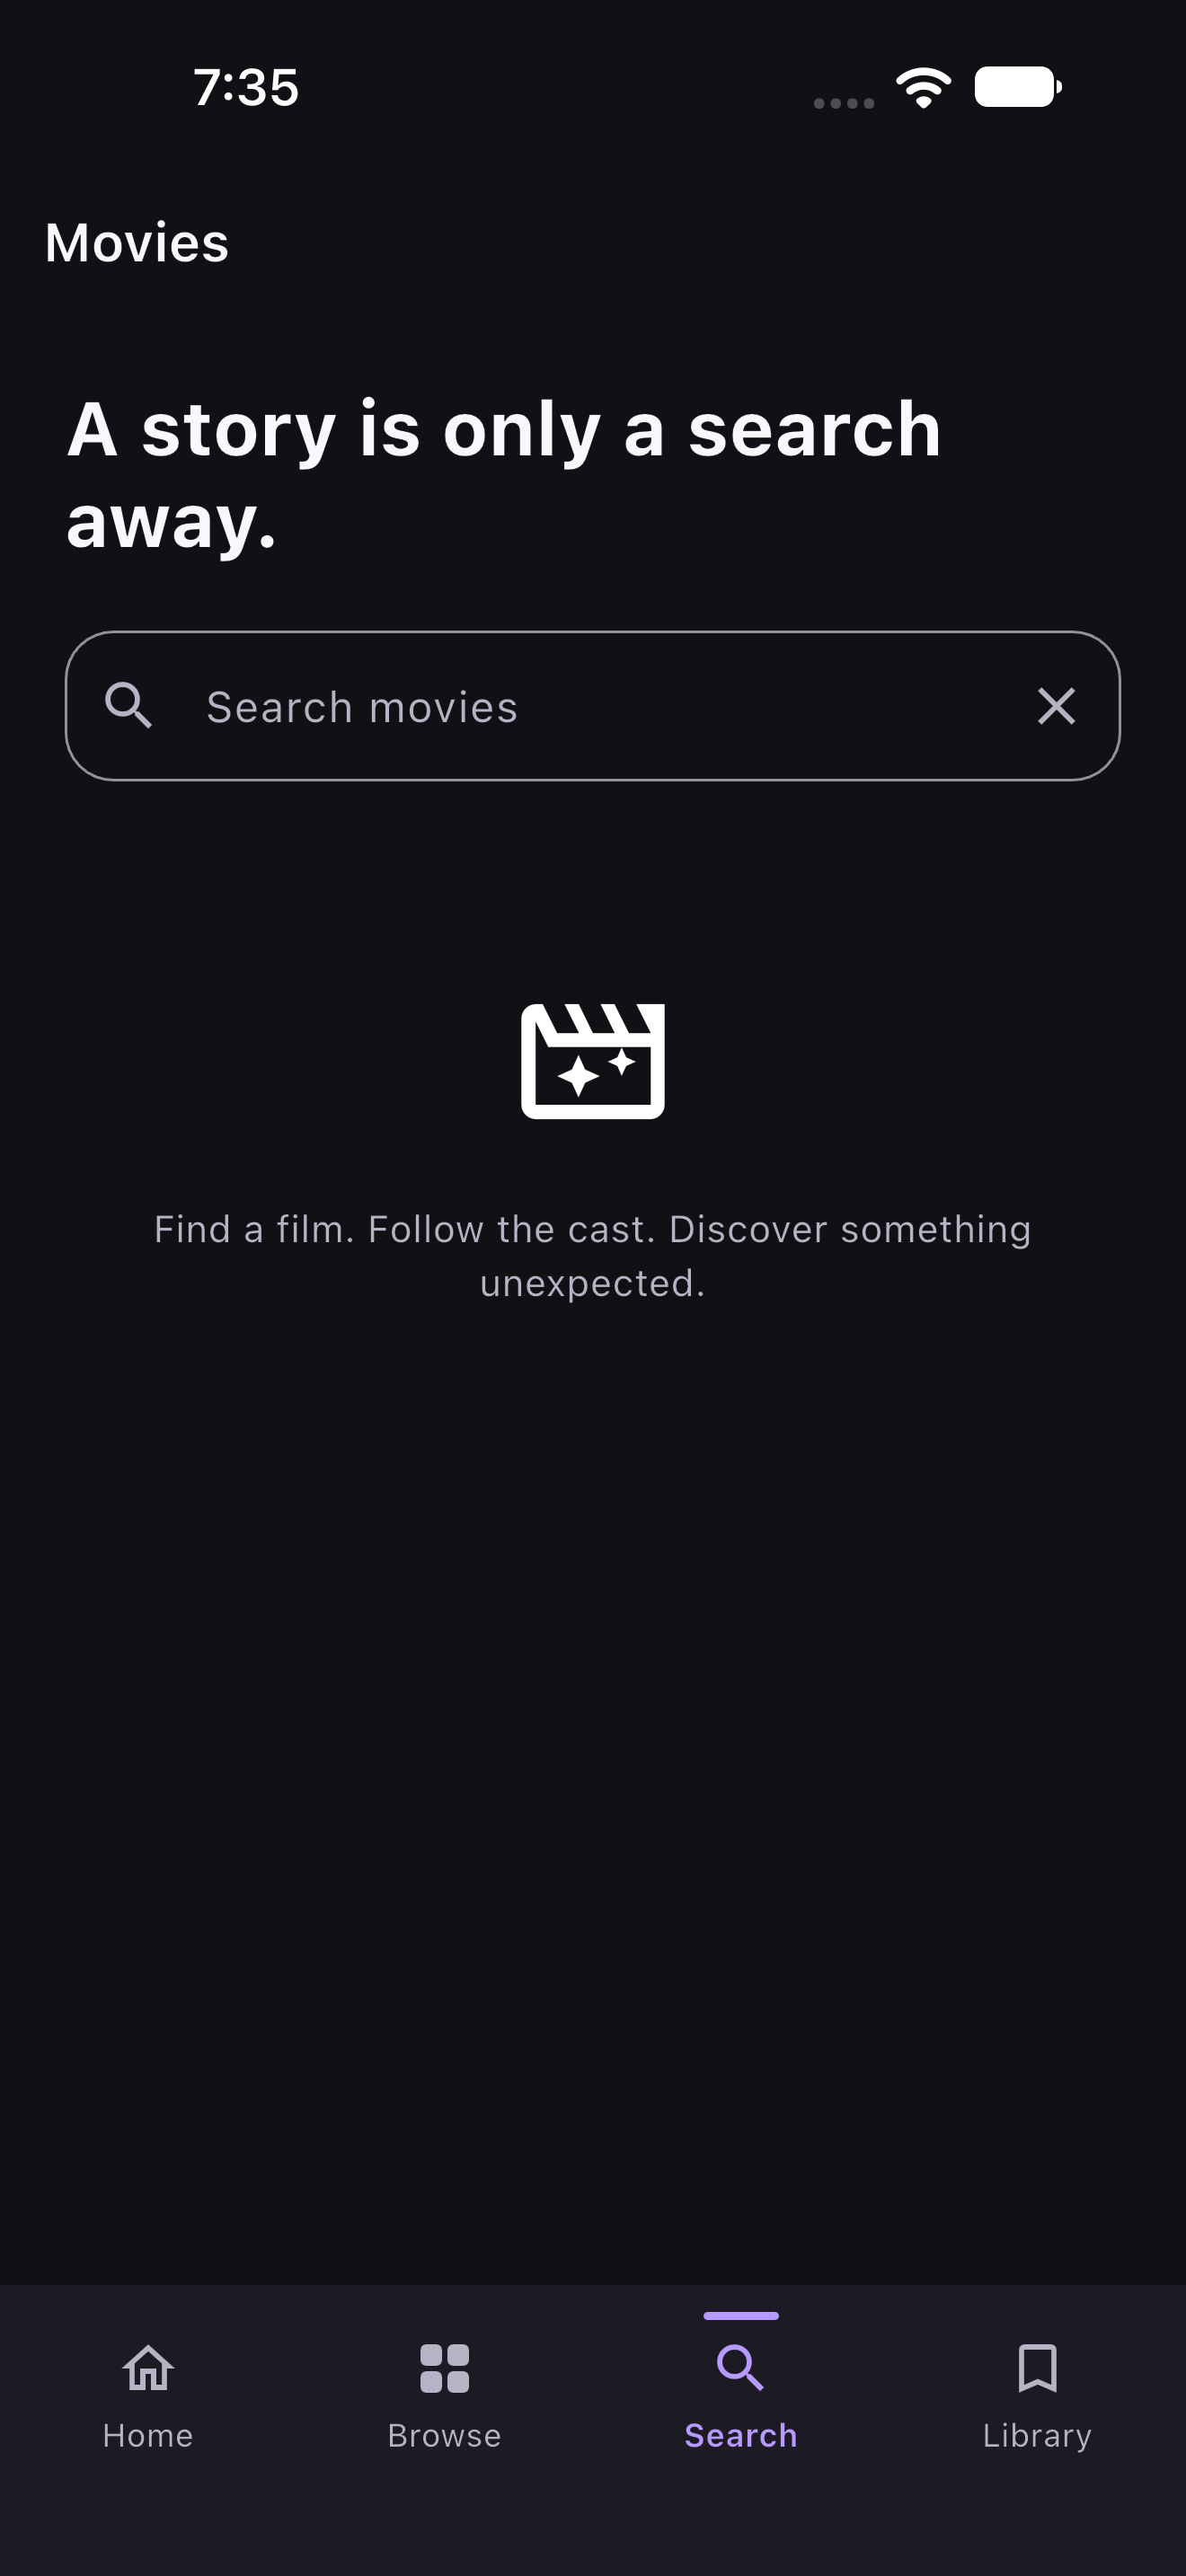

AFTER capture status: complete
Saved input evidence: [{'type': 'XCUIElementTypeTextField', 'name': 'movies.search.query.input', 'label': 'Search movies', 'value': 'Interstellar', 'visible': 'true'}]


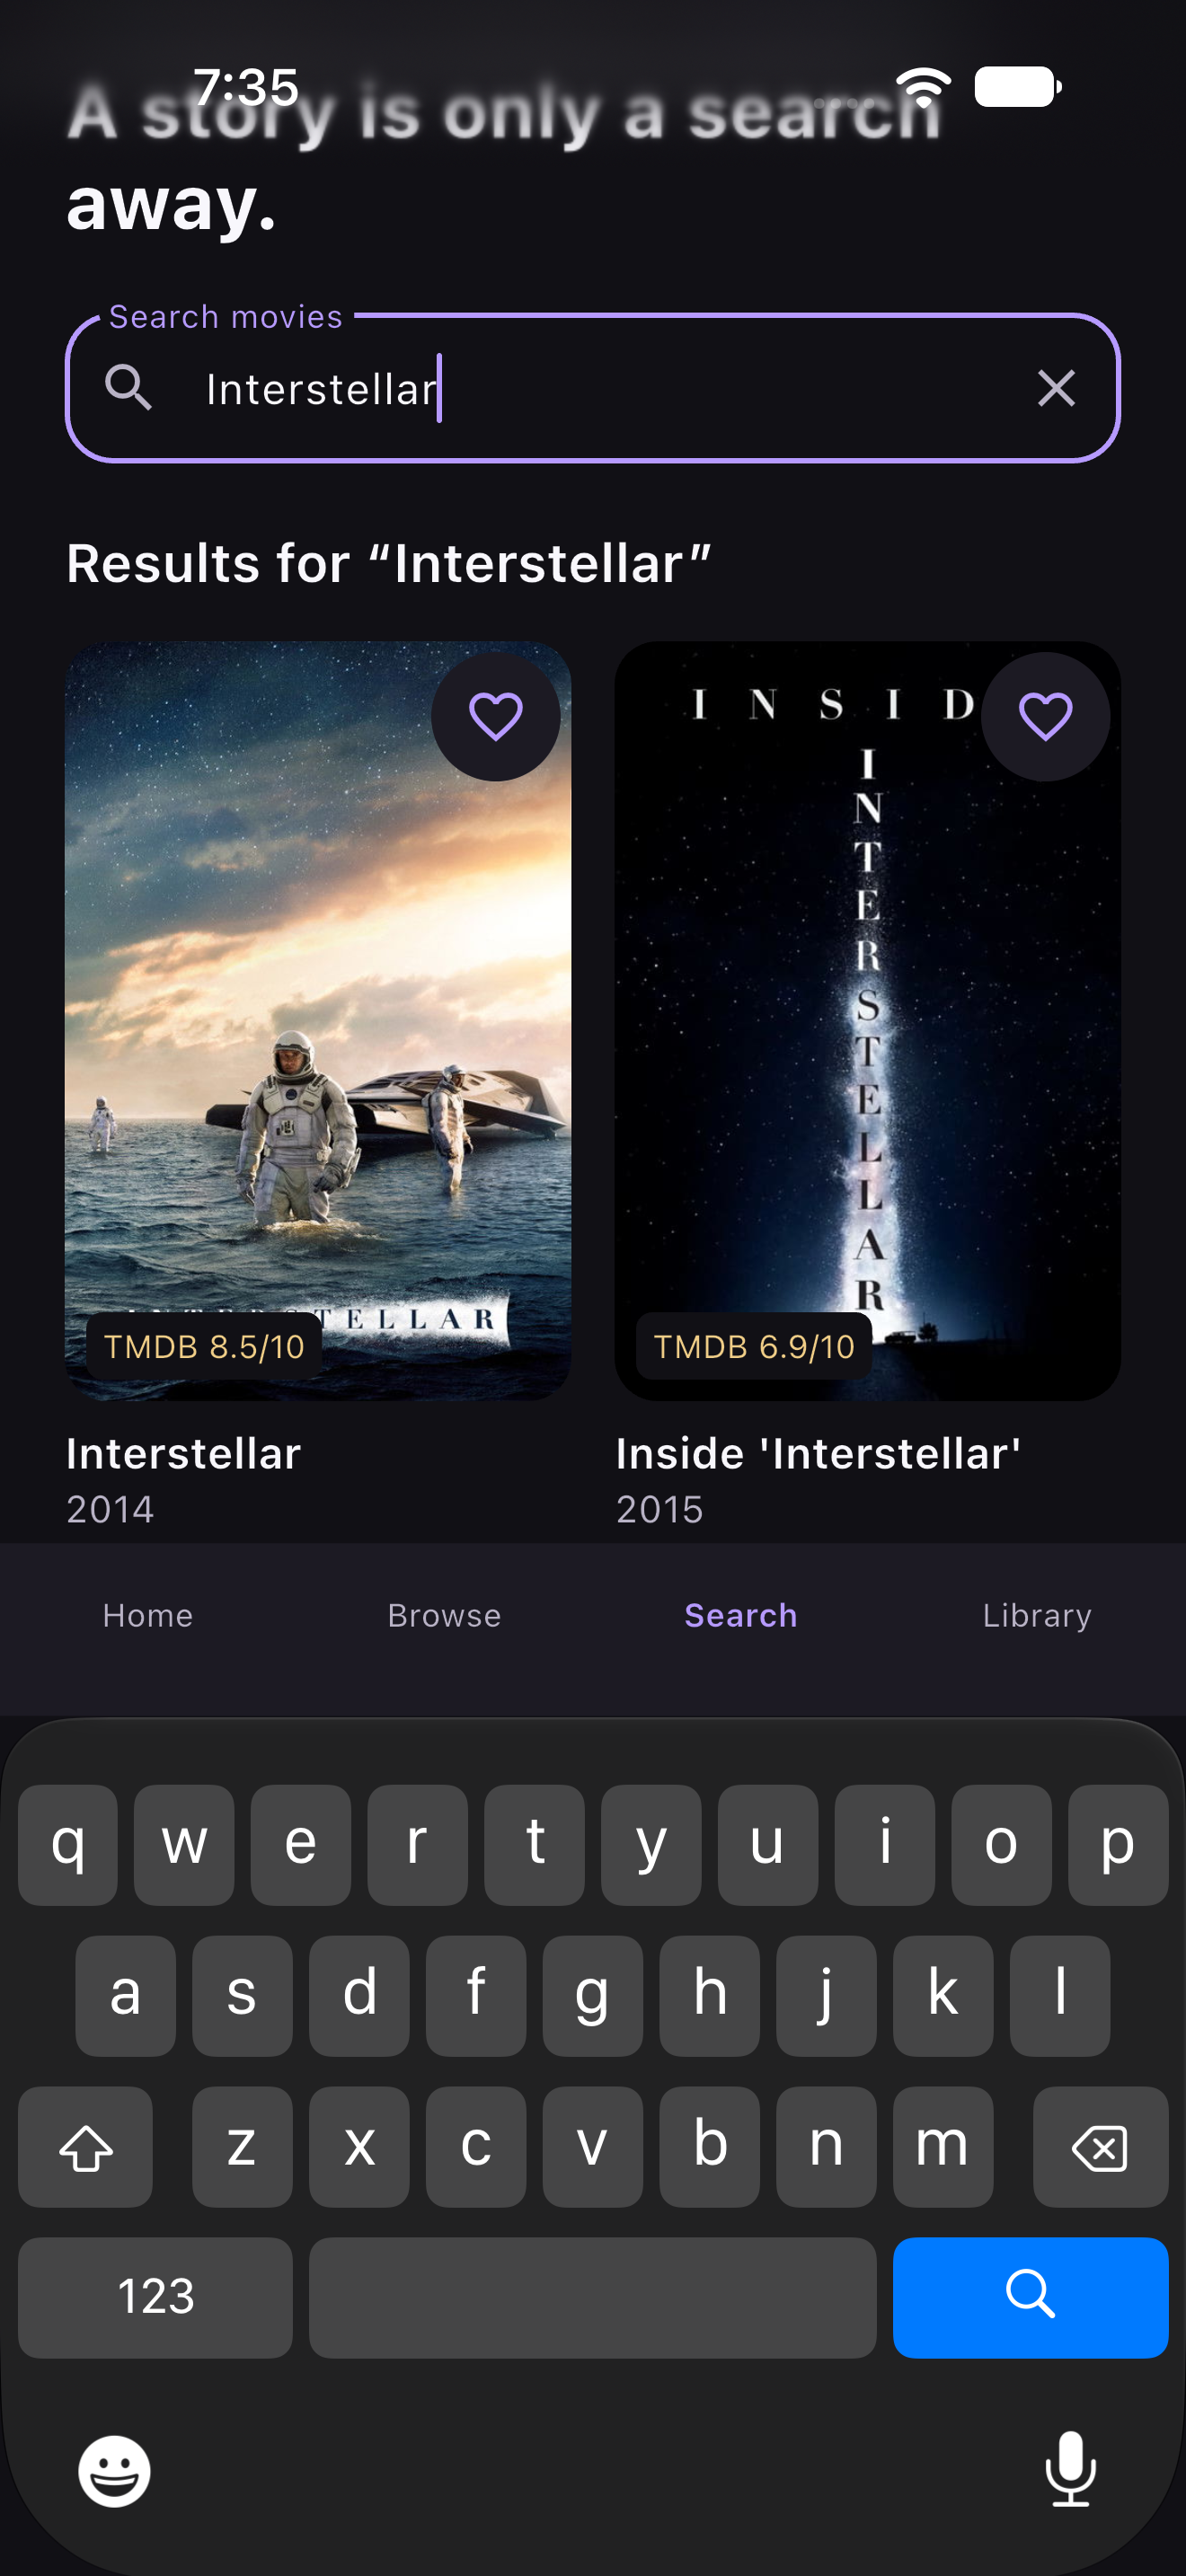

In [7]:
import json
import xml.etree.ElementTree as ET
from IPython.display import Image, display

if not isinstance(globals().get("search_result"), dict):
    raise RuntimeError("Run the search-query exercise before previewing evidence.")
saved_search = json.loads(manifest_path.read_text(encoding="utf-8"))
print("Query:", saved_search["query"])
print("Unique input matches:", saved_search.get("input_match_count"))
print("Previous field:", saved_search.get("input_before"))
print("Field after typing:", saved_search.get("input_after_type"))
print("Recorded actions:", saved_search["actions"])
print("Query verification:", saved_search["verification_status"])
print("Observed result:", json.dumps(saved_search.get("result", {}), indent=2))
for phase in ("before", "after"):
    evidence = saved_search["evidence"].get(phase, {})
    print(phase.upper(), "capture status:", evidence.get("capture_status", "not_captured"))
    if "hierarchy" in evidence:
        try:
            root = ET.parse(evidence["hierarchy"]["path"]).getroot()
            fields = [{key: node.get(key, "") for key in ("type", "name", "label", "value", "visible")}
                      for node in root.iter() if node.get("name") == saved_search["input_locator"]]
            print("Saved input evidence:", fields)
        except (ET.ParseError, OSError) as error:
            print("Hierarchy preview unavailable:", type(error).__name__)
    if "screenshot" in evidence:
        display(Image(filename=evidence["screenshot"]["path"], width=300))


### Read the search result, then pause

We have added **locate input → inspect existing value → clear if needed → type once → verify field → observe current-query results**. This is still a manually written automation exercise; no LLM interpreted the scenario or chose the locator.

An acknowledged typing command does not prove the correct text is present. Correct text does not prove results belong to it. A matching current-query heading and cards provide the next level of UI evidence. We preserve UI-reported errors and distinguish empty results, timeouts, setup failures, and input failures.

A matching `Open Interstellar` card is a title candidate, not yet proof that the selected movie is the 2014 release. We have not tapped a card or checked a details title/year. Results may come through the app's cache; this exercise does not claim a fresh TMDB request succeeded. No fixture UI or response fallback is introduced.

The session and owned Appium server are closed afterward. The query and keyboard may remain in the preserved app state. Before/after artifacts are ignored local files, and their inline previews remain readable after cleanup.

**Pause here:** the next small step will be to identify the intended movie from the actual result evidence, open it, and verify its details against the expected title/year. That is a separate exercise.


**Recorded live verification:** `2026-11-03T04:07:28.617261+00:00` (UTC). Two intentional checks covered the empty-field path and the existing-text replacement path. In the first, the field was empty and no clear command was needed. In the second, the existing value was `Interstellar`; the log records **one clear request**, **one typing request**, and **zero click requests**. Both runs observed the requested field value and current-query results, saved before/after evidence, deleted their sessions, and stopped their owned servers. These were deliberate checks, not retries after an uncertain write.

The saved output above is the replacement check. It exposed 4 visible movie-card controls and one exact-title candidate, `movies.search.results.movie.157336.open` (`Open Interstellar`). That identifier came from actual UI evidence; it was not supplied as a known TMDB ID. We have not opened it or verified the details year.

Replacement-run manifest: `/Users/tarunkhurana/Engineering/projects/tarunkhurana2015/ai-certification-gen-academy/week3-project-automated-testing/server/.tools/observations/search-query-egm6wp94/manifest.json`. Empty-field-run manifest: `/Users/tarunkhurana/Engineering/projects/tarunkhurana2015/ai-certification-gen-academy/week3-project-automated-testing/server/.tools/observations/search-query-u9mb7zlx/manifest.json`. XML/PNG artifacts are alongside each manifest and ignored by Git; the replacement run's real screenshots are embedded above. Appium exited with code `0` in both checks.


[Index](README.md) · [Previous lesson](13_search_navigation.ipynb) · [Next lesson](15_movie_details_assertions.ipynb)